In [1]:
#Soal 2
#Knowledge Base benua dan samudra
KB = {
    "northOf": {
        ("North America", "Central America"),
        ("North America", "Caribbean"),
        ("North America", "South America"),
        ("Europe", "Africa"),
        ("Europe", "Middle East"),
        ("Asia", "Australia & Oceania")
    },
    "southOf": {
        ("Central America", "North America"),
        ("Caribbean", "North America"),
        ("South America", "North America"),
        ("Africa", "Europe"),
        ("Middle East", "Europe"),
        ("Australia & Oceania", "Asia"),
        ("North America", "Antarctica"),
        ("South America", "Antarctica"),
        ("Europe", "Antarctica"),
        ("Asia", "Antarctica"),
        ("Africa", "Antarctica"),
        ("Australia & Oceania", "Antarctica")
    },
    "eastOf": {
        ("Asia", "Europe"),
        ("Asia", "Middle East"),
        ("Europe", "North America"),
        ("Africa", "South America"),
        ("Africa", "Caribbean"),
        ("Australia & Oceania", "Africa"),
        ("Australia & Oceania", "Asia"),
        ("Pacific Ocean", "Asia"),
        ("Pacific Ocean", "Australia & Oceania"),
        ("Atlantic Ocean", "North America"),
        ("Atlantic Ocean", "South America"),
        ("Indian Ocean", "Africa"),
        ("Indian Ocean", "Australia & Oceania")
    },
    "westOf": {
        ("Europe", "Asia"),
        ("Middle East", "Asia"),
        ("North America", "Europe"),
        ("South America", "Africa"),
        ("Caribbean", "Africa"),
        ("Caribbean", "Europe"),
        ("Africa", "Asia"),
        ("Asia", "Australia & Oceania"),

        ("Pacific Ocean", "North America"),
        ("Pacific Ocean", "South America"),
        ("Atlantic Ocean", "Europe"),
        ("Atlantic Ocean", "Africa"),
        ("Indian Ocean", "Australia & Oceania")
    }
}

In [2]:
#Fungsi untuk memeriksa relasi
def is_related(relation, x, y):
    return (x, y) in KB.get(relation, set())
#Fungsi menampilkan semua relasi yang melibatkan
def print_relations(entity):
    print(f"Relasi yang melibatkan: {entity}\n")
    for rel, pairs in KB.items():
        for a, b in pairs:
            if a == entity or b == entity:
                print(f"{rel}({a}, {b})")
    print()

In [3]:
#Query
print_relations("North America")
print_relations("Central America")
print_relations("Caribbean")
print_relations("South America")
print_relations("Europe")
print_relations("Africa")
print_relations("Middle East")
print_relations("Asia")
print_relations("Australia & Oceania")
print_relations("Antarctica")

Relasi yang melibatkan: North America

northOf(North America, Central America)
northOf(North America, South America)
northOf(North America, Caribbean)
southOf(South America, North America)
southOf(Caribbean, North America)
southOf(Central America, North America)
southOf(North America, Antarctica)
eastOf(Atlantic Ocean, North America)
eastOf(Europe, North America)
westOf(Pacific Ocean, North America)
westOf(North America, Europe)

Relasi yang melibatkan: Central America

northOf(North America, Central America)
southOf(Central America, North America)

Relasi yang melibatkan: Caribbean

northOf(North America, Caribbean)
southOf(Caribbean, North America)
eastOf(Africa, Caribbean)
westOf(Caribbean, Africa)
westOf(Caribbean, Europe)

Relasi yang melibatkan: South America

northOf(North America, South America)
southOf(South America, Antarctica)
southOf(South America, North America)
eastOf(Africa, South America)
eastOf(Atlantic Ocean, South America)
westOf(Pacific Ocean, South America)
westOf(

In [4]:
#Soal 3
#Input derajat keanggotaan
in1 = [0.4, 0.6]   #Persediaan: Sedikit=0.4, Banyak=0.6
in2 = [0.3, 0.7]   #Permintaan: Turun=0.3, Naik=0.7

In [5]:
#Hitung apred
apred1 = min(in1[1], in2[1])  #Banyak dan Naik
apred2 = min(in1[0], in2[0])  #Sedikit dan Turun
apred3 = min(in1[0], in2[1])  #Sedikit dan Naik
apred4 = min(in1[1], in2[0])  #Banyak dan Turun

In [6]:
#Hitung output z
z1 = 5000 * apred1 + 2000          #Produksi Tinggi
z2 = 7000 - 5000 * apred2          #Produksi Rendah
z3 = 4000 + 3000 * apred3          #Produksi Sedang
z4 = 7000 - 3000 * apred4          #Produksi Sedang cenderung Rendah

In [7]:
#Defuzzifikasi
numerator = apred1*z1 + apred2*z2 + apred3*z3 + apred4*z4
denominator = apred1 + apred2 + apred3 + apred4
z_defuzz = numerator / denominator if denominator != 0 else None

In [8]:
# Tampilkan hasil
print("apred1, apred2, apred3, apred4 =",
      apred1, apred2, apred3, apred4)
print("z1, z2, z3, z4 =",
      z1, z2, z3, z4)
print("Numerator =", numerator)
print("Denominator =", denominator)
print("Nilai defuzzifikasi z =", z_defuzz)

apred1, apred2, apred3, apred4 = 0.6 0.3 0.4 0.3
z1, z2, z3, z4 = 5000.0 5500.0 5200.0 6100.0
Numerator = 8560.0
Denominator = 1.5999999999999999
Nilai defuzzifikasi z = 5350.0


In [9]:
#Soal 4
#Library
import numpy as np
import matplotlib.pyplot as plt

In [10]:
#MF function
def trap_mf(x, a, b, c, d):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    #Rising
    idx = (x >= a) & (x <= b)
    if b != a:
        y[idx] = (x[idx] - a) / (b - a)
    #Top
    idx = (x >= b) & (x <= c)
    y[idx] = 1.0
    #Falling
    idx = (x >= c) & (x <= d)
    if d != c:
        y[idx] = (d - x[idx]) / (d - c)
    return np.clip(y, 0, 1)

def tri_mf(x, a, b, c):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    #Rising slope
    idx = (x >= a) & (x <= b)
    if b != a:
        y[idx] = (x[idx] - a) / (b - a)
    #Falling slope
    idx = (x >= b) & (x <= c)
    if c != b:
        y[idx] = (c - x[idx]) / (c - b)
    #Peak
    y[x == b] = 1.0
    return np.clip(y, 0, 1)

In [11]:
#Domain variables
speed_x = np.linspace(0, 180, 361)
road_x  = np.linspace(0, 10, 101)
risk_x  = np.linspace(0, 100, 501)

In [12]:
#Membership function
speed_mf = {
    "slow":   lambda x: tri_mf(x, 0, 0, 60),
    "medium": lambda x: tri_mf(x, 40, 90, 140),
    "fast":   lambda x: tri_mf(x, 120, 180, 180)
}
road_mf = {
    "poor":   lambda x: tri_mf(x, 0, 2, 4),
    "normal": lambda x: tri_mf(x, 2, 5, 8),
    "good":   lambda x: tri_mf(x, 6, 8, 10)
}
risk_mf = {
    "low":  lambda x: trap_mf(x, 0, 0, 30, 50),
    "high": lambda x: trap_mf(x, 30, 50, 100, 100)
}

In [13]:
#Fuzzification
def fuzzify_speed(v):
    v = np.array([float(v)])
    # NumPy >= 2 refuses float() on a size-1 array, so take the element explicitly.
    return {name: float(np.asarray(mf(v)).ravel()[0]) for name, mf in speed_mf.items()}

def fuzzify_road(v):
    v = np.array([float(v)])
    # NumPy >= 2 refuses float() on a size-1 array, so take the element explicitly.
    return {name: float(np.asarray(mf(v)).ravel()[0]) for name, mf in road_mf.items()}

In [14]:
#Rule base
rules = [
    (("slow", "good"),   "low"),
    (("slow", "normal"), "low"),
    (("slow", "poor"),   "high"),

    (("medium", "good"),   "low"),
    (("medium", "normal"), "high"),
    (("medium", "poor"),   "high"),

    (("fast", "good"),   "high"),
    (("fast", "normal"), "high"),
    (("fast", "poor"),   "high"),
]

In [15]:
#Inference (mamdani)
def apply_rules(speed_val, road_val):
    ms = fuzzify_speed(speed_val)
    mr = fuzzify_road(road_val)
    aggregated = np.zeros_like(risk_x)
    activations = []
    for (s_lbl, r_lbl), risk_lbl in rules:
        alpha = min(ms[s_lbl], mr[r_lbl])
        activations.append(((s_lbl, r_lbl), risk_lbl, alpha))
        if alpha > 0:
            clipped = np.minimum(risk_mf[risk_lbl](risk_x), alpha)
            aggregated = np.maximum(aggregated, clipped)
    return ms, mr, activations, aggregated

In [16]:
#Defuzzification (centroid)
def defuzzify_centroid(agg):
    num = np.sum(risk_x * agg)
    den = np.sum(agg)
    return 0 if den == 0 else num / den

In [17]:
#Evaluation
def evaluate_case(speed, road, plot=False):
    ms, mr, acts, agg = apply_rules(speed, road)
    crisp = defuzzify_centroid(agg)
    if plot:
        plot_aggregation(agg, crisp, speed, road)
    return {
        "speed": speed,
        "road": road,
        "mu_speed": ms,
        "mu_road": mr,
        "rule_activations": acts,
        "risk_crisp": crisp,
        "aggregated": agg
    }

In [18]:
#Visualization
def plot_mfs():
    plt.figure(figsize=(12, 8))
    plt.subplot(3, 1, 1)
    for n, mf in speed_mf.items():
        plt.plot(speed_x, mf(speed_x), label=n)
    plt.title("Speed MF"); plt.grid(); plt.legend()
    plt.subplot(3, 1, 2)
    for n, mf in road_mf.items():
        plt.plot(road_x, mf(road_x), label=n)
    plt.title("Road Condition MF"); plt.grid(); plt.legend()
    plt.subplot(3, 1, 3)
    for n, mf in risk_mf.items():
        plt.plot(risk_x, mf(risk_x), label=n)
    plt.title("Risk MF"); plt.grid(); plt.legend()
    plt.tight_layout()

def plot_aggregation(agg, crisp, speed, road):
    plt.figure(figsize=(8, 4))
    plt.plot(risk_x, agg, label="Aggregated")
    plt.fill_between(risk_x, 0, agg, alpha=0.3)
    for n, mf in risk_mf.items():
        plt.plot(risk_x, mf(risk_x), '--', label=n)
    plt.axvline(crisp, color='k', linestyle=':')
    plt.title(f"Risk Aggregation (speed={speed}, road={road})")
    plt.grid(); plt.legend()
    plt.tight_layout()

Kasus A 22.542350332594232
Kasus B 38.99024103468548
Kasus: 67.48602150537634


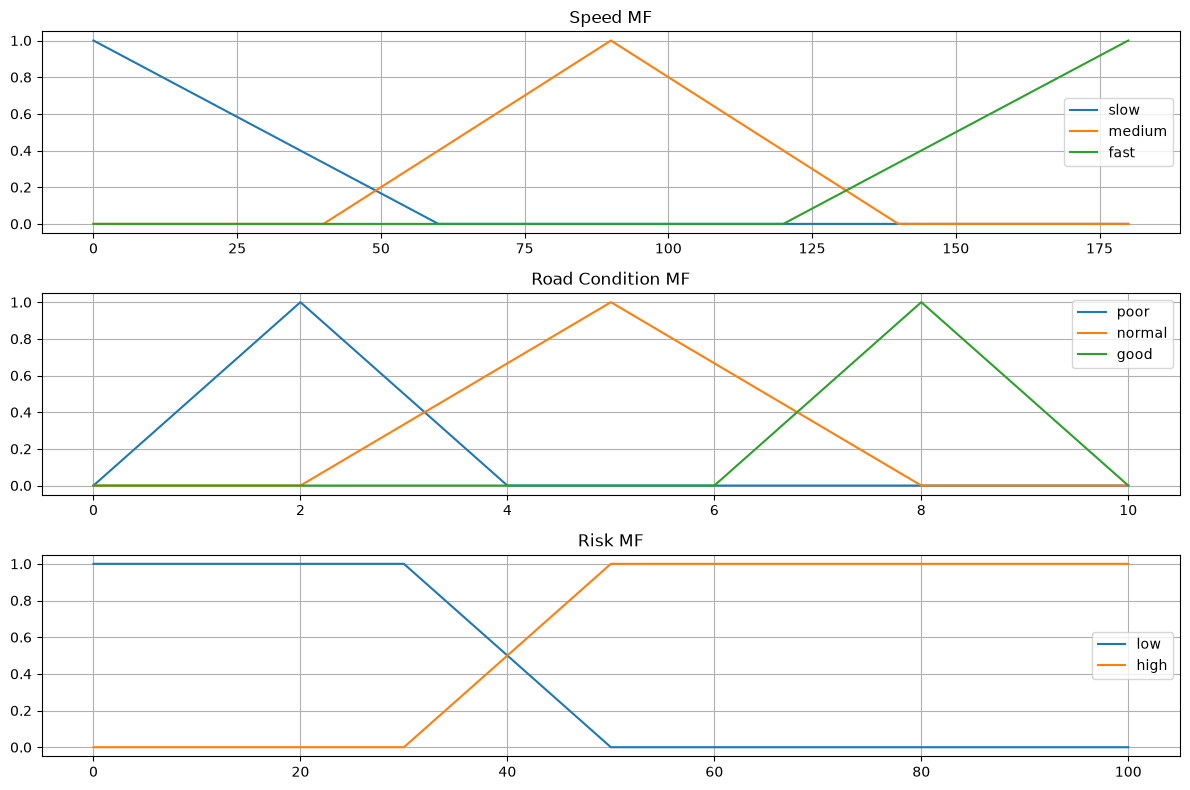

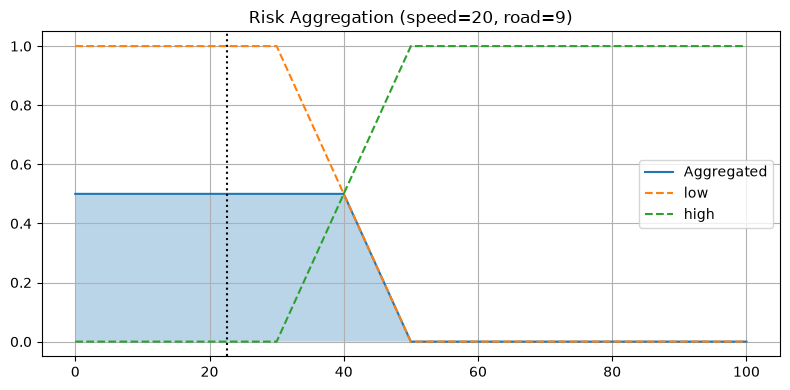

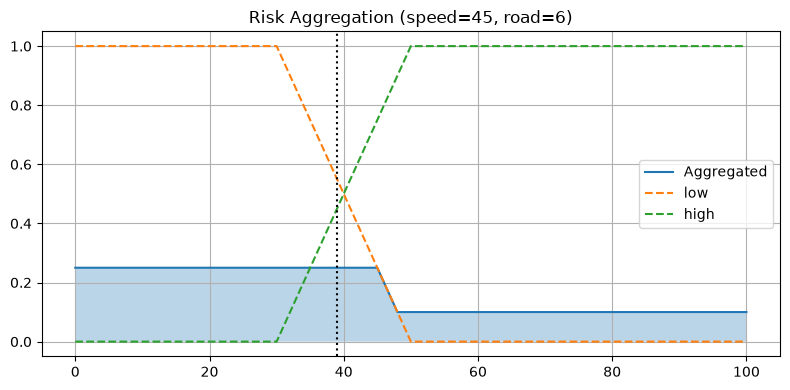

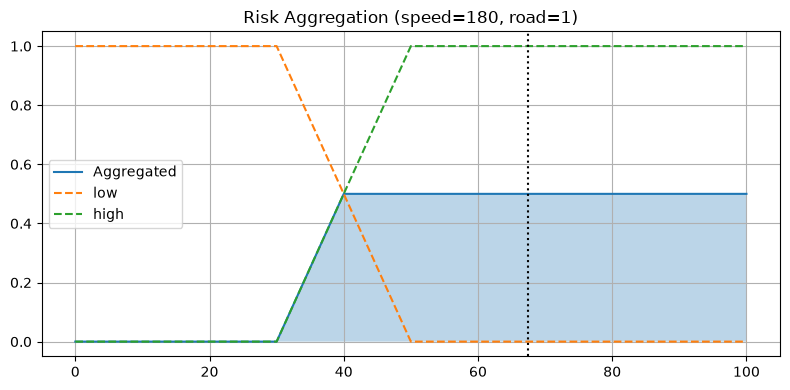

In [19]:
#Evaluate each case
if __name__ == "__main__":
    plot_mfs()
    plt.savefig("mf_plot.png", dpi=150)
    LowRisk  = evaluate_case(20,  9, plot=True)
    plt.savefig("case_NoRisk.png", dpi=150)
    ModerateRisk = evaluate_case(45,  6, plot=True)
    plt.savefig("case_LowRisk.png", dpi=150)
    HighRisk = evaluate_case(180, 1, plot=True)
    plt.savefig("case_HighRisk.png", dpi=150)
    print("Kasus A",  LowRisk["risk_crisp"])
    print("Kasus B", ModerateRisk["risk_crisp"])
    print("Kasus:", HighRisk["risk_crisp"])